Module 4: Evaluation Homework: Lead Scoring Evaluation

In [1]:
import pandas as pd
import numpy as np

In [7]:
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'

In [2]:
!wget $data

--2026-10-31 10:09:34--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.109.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘course_lead_scoring_2026.csv’

course_lead_scoring 100%[===================>] 272.21K  --.-KB/s    in 0.04s   

2026-10-31 10:09:37 (6.34 MB/s) - ‘course_lead_scoring_2026.csv’ saved [278746/278746]



In [2]:
df = pd.read_csv('course_lead_scoring_2026.csv')

In [3]:
df.head(10)

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1
5,referral,manufacturing,employed,africa,43841.0,3,5,0.77,1
6,NaN,education,employed,north_america,58738.0,3,9,0.78,1
7,paid_ads,technology,employed,north_america,95059.0,2,4,0.41,1
8,organic_search,healthcare,employed,asia,62565.0,3,6,0.52,1
9,referral,retail,student,asia,12000.0,2,2,0.35,0


Data Preparation

In [4]:
missing_values = df.isna().sum()
missing_values = missing_values[missing_values > 0]

print(missing_values)

lead_source          148
industry             240
employment_status    194
location             208
annual_income        369
lead_score            35
dtype: int64


In [5]:
categorical_columns = ['lead_source', 'industry', 'employment_status', 'location']
numerical_columns = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

In [6]:
df[categorical_columns] = df[categorical_columns].fillna("NA")
df[numerical_columns] = df[numerical_columns].fillna(0.0)

In [7]:
print(df.isna().sum())

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64


In [8]:
from sklearn.model_selection import train_test_split

In [9]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [10]:
y_train = df_train['converted'].values         
y_val = df_val['converted'].values
y_test = df_test['converted'].values

In [11]:
del df_train['converted']
del df_val['converted']
del df_test['converted']

Question 1: ROC AUC Feature Importance

In [12]:
from sklearn.metrics import roc_auc_score

auc_scores = {}

for feature in numerical_columns:
    score = df_train[feature]
    auc = roc_auc_score(y_train, score)

    if auc < 0.5:
        score = -score
        auc = roc_auc_score(y_train, score)

    auc_scores[feature] = auc

pd.Series(auc_scores).sort_values(ascending=False)

lead_score                  0.788225
interaction_count           0.764920
number_of_courses_viewed    0.722989
annual_income               0.608198
dtype: float64

Question 2: Training the Model

In [13]:
from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer(sparse=False)

dicts = df_train[categorical_columns].to_dict(orient='records')

X_train = dv.fit_transform(dicts)

In [14]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [15]:
X_val = dv.transform(df_val[categorical_columns].to_dict(orient='records'))
y_val_pred = model.predict_proba(X_val)[:, 1]

In [16]:
from sklearn.metrics import roc_auc_score

auc = roc_auc_score(y_val, y_val_pred)
print(f"AUC: {auc:.3f}")

AUC: 0.687


In [17]:
print(0.687 - 0.632)
print(0.687 - 0.732)

0.05500000000000005
-0.04499999999999993


Question 3: Precision and Recall

In [18]:
from sklearn.metrics import auc

In [19]:
from sklearn.metrics import precision_score, recall_score, confusion_matrix

# Convert predicted probabilities into 0/1 predictions
y_val_pred_binary = (y_val_pred >= 0.5).astype(int)

precision = precision_score(y_val, y_val_pred_binary)
recall = recall_score(y_val, y_val_pred_binary)

print(f"Precision: {precision:.3f}")
print(f"Recall: {recall:.3f}")

print("Confusion matrix:")
print(confusion_matrix(y_val, y_val_pred_binary))

Precision: 0.666
Recall: 0.788
Confusion matrix:
[[182 232]
 [124 462]]


In [20]:
thresholds = np.arange(0.0, 1.0, 0.01)

results = []

for t in thresholds:
    y_val_pred_binary = (y_val_pred >= t).astype(int)

    precision = precision_score(y_val, y_val_pred_binary, zero_division=0)
    recall = recall_score(y_val, y_val_pred_binary, zero_division=0)

    results.append({
        "threshold": t,
        "precision": precision,
        "recall": recall
    })

results_df = pd.DataFrame(results)
results_df.head(10)

,threshold,precision,recall
0,0.00,0.586,1.0
1,0.01,0.586,1.0
2,0.02,0.586,1.0
3,0.03,0.586,1.0
4,0.04,0.586,1.0
5,0.05,0.586,1.0
6,0.06,0.586,1.0
7,0.07,0.586,1.0
8,0.08,0.586,1.0
9,0.09,0.586,1.0


In [21]:
import matplotlib.pyplot as plt

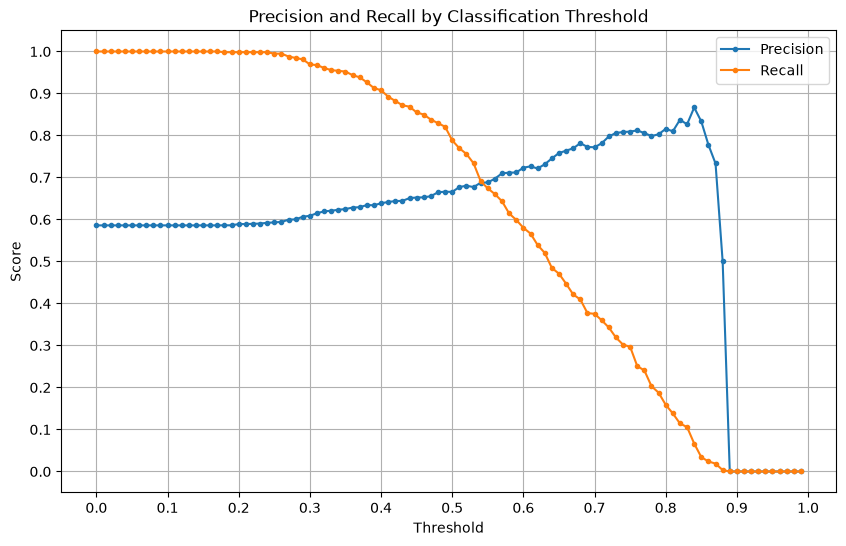

In [22]:
plt.figure(figsize=(10, 6))

plt.plot(
    results_df["threshold"],
    results_df["precision"],
    label="Precision",
    marker="."
)

plt.plot(
    results_df["threshold"],
    results_df["recall"],
    label="Recall",
    marker="."
)

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall by Classification Threshold")
plt.xticks(np.arange(0.0, 1.1, 0.1))
plt.yticks(np.arange(0.0, 1.1, 0.1))
plt.grid(True)
plt.legend()
plt.show()

Question 4: F1 Score

In [23]:
from sklearn.metrics import f1_score

In [ ]:
f1 = f1_score(
    y_val,
    y_val_pred_binary,
    zero_division=0
)

In [24]:
thresholds = np.arange(0.0, 1.01, 0.01)

f1_results = []

for threshold in thresholds:
    y_val_pred_binary = (y_val_pred >= threshold).astype(int)

    f1 = f1_score(
        y_val,
        y_val_pred_binary,
        zero_division=0
    )

    f1_results.append({
        "threshold": threshold,
        "f1": f1
    })

f1_results_df = pd.DataFrame(f1_results)

f1_results_df

,threshold,f1
0,0.00,0.738966
1,0.01,0.738966
2,0.02,0.738966
3,0.03,0.738966
4,0.04,0.738966
...,...,...
96,0.96,0.000000
97,0.97,0.000000
98,0.98,0.000000
99,0.99,0.000000


In [25]:
print(0.32 - 0.21)
print(0.32 - 0.41)

0.11000000000000001
-0.08999999999999997


Question 5: 5 Fold Cross Validation

In [26]:
from sklearn.model_selection import KFold

In [28]:
from tqdm.auto import tqdm

In [29]:
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

C_values = [0.001, 0.01, 0.1, 1, 10, 100]

for C in tqdm(C_values, desc="Evaluating C values"):
    scores = []

    for train_idx, val_idx in kf.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train["converted"].values
        y_val = df_val["converted"].values

        train_dicts = df_train.drop(
            columns=["converted"]
        ).to_dict(orient="records")

        val_dicts = df_val.drop(
            columns=["converted"]
        ).to_dict(orient="records")

        dv = DictVectorizer(sparse=False)

        X_train = dv.fit_transform(train_dicts)
        X_val = dv.transform(val_dicts)

        model = LogisticRegression(
            solver="liblinear",
            C=C,
            max_iter=1000
        )

        model.fit(X_train, y_train)

        y_val_pred = model.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_val_pred)

        scores.append(auc)

    mean_auc = np.mean(scores)
    std_auc = np.std(scores)

    print(
        f"C={C}: "
        f"mean AUC={mean_auc:.3f}, "
        f"std={std_auc:.3f}"
    )

Evaluating C values:   0%|          | 0/6 [00:00<?, ?it/s]

C=0.001: mean AUC=0.749, std=0.010
C=0.01: mean AUC=0.733, std=0.007
C=0.1: mean AUC=0.732, std=0.007
C=1: mean AUC=0.732, std=0.007
C=10: mean AUC=0.732, std=0.007
C=100: mean AUC=0.732, std=0.007
